# Modelling: predicting the number of rings of an abalone

First version of a model predicting the number of `rings` (age in years ≈ rings + 1.5) from the
physical measurements. Following the conclusions of the [EDA notebook](eda.ipynb), we:
- drop the 4 rows with an impossible or extreme height
- one-hot encode the sex
- compare a few simple regression models to a baseline, on a held-out test set

The preprocessing and training code is written as small functions, so that it can be moved to
`src/modelling/preprocessing.py` and `src/modelling/training.py` in the next step.

## Experiment tracking with MLflow

Every model is logged as an MLflow run (parameters and test metrics) in `mlflow.db` at the root
of the repository, which is git-ignored. To compare the runs in the MLflow UI, run this from the
root of the repository and open http://127.0.0.1:5001:

```bash
uv run mlflow ui --backend-store-uri sqlite:///mlflow.db --port 5001
```

(Port 5000, the MLflow default, is used by AirPlay on macOS.)

# Imports

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import mlflow
import pandas as pd
from sklearn.base import RegressorMixin
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder

# Configuration

In [2]:
REPO_ROOT = Path.cwd().parent
DATA_PATH = REPO_ROOT / "data" / "abalone.csv"

CATEGORICAL_COLS = ["sex"]
NUMERICAL_COLS = [
    "length",
    "diameter",
    "height",
    "whole_weight",
    "shucked_weight",
    "viscera_weight",
    "shell_weight",
]
TARGET_COL = "rings"

TEST_SIZE = 0.2
RANDOM_STATE = 42

EXPERIMENT_NAME = "abalone-age-prediction"

In [3]:
mlflow.set_tracking_uri(f"sqlite:///{REPO_ROOT / 'mlflow.db'}")
experiment = mlflow.set_experiment(EXPERIMENT_NAME)
print(f"Logging to experiment '{experiment.name}' (id {experiment.experiment_id})")

2026/10/22 11:26:56 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/10/22 11:26:56 INFO mlflow.store.db.utils: Updating database tables


2026/10/22 11:26:56 INFO mlflow.tracking.fluent: Experiment with name 'abalone-age-prediction' does not exist. Creating a new experiment.


Logging to experiment 'abalone-age-prediction' (id 1)


# Data

In [4]:
df = pd.read_csv(DATA_PATH)
df.head()

,Sex,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7


# Preprocessing

In [5]:
def clean_column_names(df: pd.DataFrame) -> pd.DataFrame:
    """Lower-case the column names and replace spaces with underscores."""
    return df.rename(columns=lambda col: col.strip().lower().replace(" ", "_"))


def remove_outliers(df: pd.DataFrame) -> pd.DataFrame:
    """Drop the rows with an impossible (0) or extreme (> 0.4) height spotted in the EDA."""
    return df[(df["height"] > 0) & (df["height"] <= 0.4)]


def fit_encoder(df: pd.DataFrame) -> OneHotEncoder:
    """Fit a one-hot encoder on the categorical columns."""
    encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    encoder.set_output(transform="pandas")
    return encoder.fit(df[CATEGORICAL_COLS])


def build_features(df: pd.DataFrame, encoder: OneHotEncoder) -> pd.DataFrame:
    """Build the feature matrix: numerical columns followed by the encoded categorical ones."""
    encoded = encoder.transform(df[CATEGORICAL_COLS])
    return pd.concat([df[NUMERICAL_COLS], encoded], axis=1)

The encoder is fitted on the training set only, so that the test set stays truly unseen.
`handle_unknown="ignore"` encodes an unexpected sex value as all zeros instead of failing.

In [6]:
df = clean_column_names(df)
df = remove_outliers(df)
print(f"{len(df)} rows after removing the outliers")

train_df, test_df = train_test_split(df, test_size=TEST_SIZE, random_state=RANDOM_STATE)
print(f"Train: {len(train_df)} rows, test: {len(test_df)} rows")

encoder = fit_encoder(train_df)
X_train, y_train = build_features(train_df, encoder), train_df[TARGET_COL]
X_test, y_test = build_features(test_df, encoder), test_df[TARGET_COL]
X_train.head()

4173 rows after removing the outliers
Train: 3338 rows, test: 835 rows


,length,diameter,height,whole_weight,shucked_weight,viscera_weight,shell_weight,sex_F,sex_I,sex_M
554,0.485,0.390,0.125,0.5910,0.2870,0.1410,0.1200,0.0,1.0,0.0
3074,0.675,0.520,0.145,1.3645,0.5570,0.3405,0.3850,0.0,0.0,1.0
2405,0.655,0.515,0.145,1.2500,0.5265,0.2830,0.3150,0.0,1.0,0.0
1956,0.645,0.490,0.175,1.3200,0.6525,0.2375,0.3385,0.0,0.0,1.0
1947,0.635,0.500,0.165,1.2730,0.6535,0.2130,0.3650,0.0,0.0,1.0


# Training and evaluation

In [7]:
def train_model(model: RegressorMixin, X: pd.DataFrame, y: pd.Series) -> RegressorMixin:
    """Fit a scikit-learn regressor on the given features and target."""
    return model.fit(X, y)


def evaluate_model(model: RegressorMixin, X: pd.DataFrame, y: pd.Series) -> dict[str, float]:
    """Compute the RMSE, MAE and R² of the model's predictions."""
    y_pred = model.predict(X)
    return {
        "rmse": root_mean_squared_error(y, y_pred),
        "mae": mean_absolute_error(y, y_pred),
        "r2": r2_score(y, y_pred),
    }

## Experiments

We compare:
- a **baseline** that always predicts the mean number of rings of the training set, to know what
  "no model" scores
- a **linear regression**, as suggested for this first version
- two tree-based models, **random forest** and **gradient boosting**, which can capture the
  non-linear relationships seen in the EDA

The main metric is the RMSE, expressed in number of rings.

In [8]:
models = {
    "baseline_mean": DummyRegressor(strategy="mean"),
    "linear_regression": LinearRegression(),
    "random_forest": RandomForestRegressor(
        n_estimators=200, min_samples_leaf=5, random_state=RANDOM_STATE, n_jobs=-1
    ),
    "gradient_boosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
}

for run_name, model in models.items():
    with mlflow.start_run(run_name=run_name):
        mlflow.log_params({"model_class": type(model).__name__, **model.get_params()})
        mlflow.log_params(
            {"test_size": TEST_SIZE, "split_random_state": RANDOM_STATE, "n_train": len(X_train)}
        )

        model = train_model(model, X_train, y_train)
        metrics = evaluate_model(model, X_test, y_test)

        mlflow.log_metrics(metrics)

    print(f"{run_name:<18} " + "  ".join(f"{name}={value:.3f}" for name, value in metrics.items()))

baseline_mean      rmse=3.463  mae=2.541  r2=-0.001
linear_regression  rmse=2.229  mae=1.584  r2=0.585


random_forest      rmse=2.199  mae=1.514  r2=0.596


gradient_boosting  rmse=2.219  mae=1.533  r2=0.589


## Comparing the runs

The same comparison can be done in the MLflow UI. Here we query the latest run of each model.

In [9]:
runs = mlflow.search_runs(experiment_names=[EXPERIMENT_NAME], order_by=["start_time DESC"])
runs = runs.drop_duplicates("tags.mlflow.runName").sort_values("metrics.rmse")
runs[["tags.mlflow.runName", "metrics.rmse", "metrics.mae", "metrics.r2"]].reset_index(drop=True)

,tags.mlflow.runName,metrics.rmse,metrics.mae,metrics.r2
0,random_forest,2.199096,1.513984,0.596422
1,gradient_boosting,2.218861,1.533259,0.589135
2,linear_regression,2.229197,1.584091,0.585298
3,baseline_mean,3.463206,2.541215,-0.000912


## Selected model: linear regression

All the models are far better than the baseline (RMSE from 3.46 down to about 2.2 rings), but
they are very close to each other: the random forest is only 0.03 rings better than the linear
regression. We keep the **linear regression** for this first version because:
- the gain of the other models is negligible compared to the error itself (about 2.2 rings)
- it is tiny once pickled (about 1 KB, against about 10 MB for the random forest). The model will
  be committed in the repository for the API, and the pre-commit hooks reject files over 500 KB.
- it is fast to train and simple to explain

## Errors of the selected model

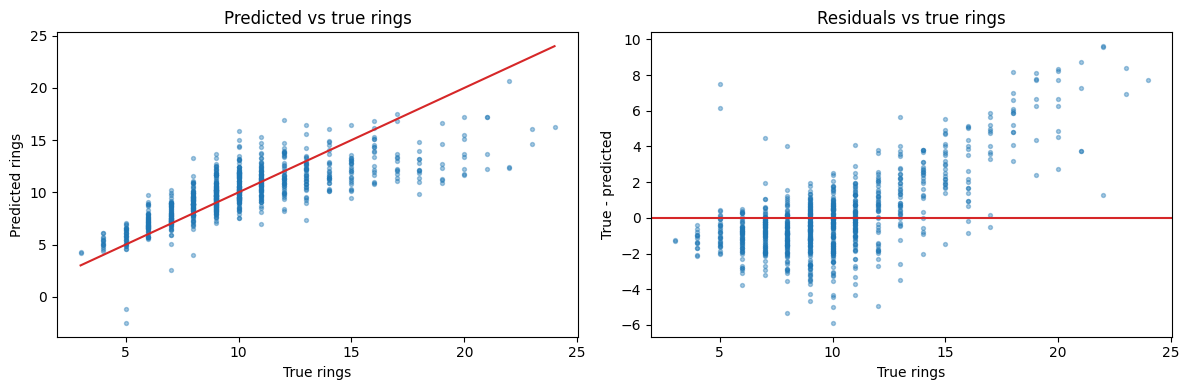

Predictions below 1 ring: 2


,mean,std,count
rings,,,
"(0, 7]",-0.833092,1.257208,186
"(7, 10]",-0.765220,1.368980,361
"(10, 13]",0.330533,1.685903,171
"(13, 30]",3.709388,2.508747,117


In [10]:
selected_model = models["linear_regression"]
y_pred = selected_model.predict(X_test)
residuals = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(y_test, y_pred, s=8, alpha=0.4)
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="tab:red")
axes[0].set(title="Predicted vs true rings", xlabel="True rings", ylabel="Predicted rings")
axes[1].scatter(y_test, residuals, s=8, alpha=0.4)
axes[1].axhline(0, color="tab:red")
axes[1].set(title="Residuals vs true rings", xlabel="True rings", ylabel="True - predicted")
plt.tight_layout()
plt.show()

print("Predictions below 1 ring:", (y_pred < 1).sum())
rings_bins = pd.cut(y_test, bins=[0, 7, 10, 13, 30])
residuals.groupby(rings_bins, observed=True).agg(["mean", "std", "count"])

The errors depend strongly on the age:
- young abalones (up to 10 rings) are slightly overestimated, by about 0.8 rings on average
- old abalones (more than 13 rings) are underestimated, by 3.7 rings on average

This was expected from the EDA: there are few old abalones and their size barely grows anymore,
so the model pulls their predictions towards the mean.

A linear model can also predict fewer than 1 ring for the smallest infants (2 test predictions
here), so predictions should be clipped to at least 1 ring at inference time.

In [11]:
pd.Series(selected_model.coef_, index=X_train.columns).sort_values()

shucked_weight   -19.155559
viscera_weight   -11.695743
length            -3.246609
sex_I             -0.465554
sex_F              0.202498
sex_M              0.263055
shell_weight       6.450873
whole_weight       9.265563
diameter          11.594953
height            23.983064
dtype: float64

The coefficients illustrate the multicollinearity seen in the EDA: the meat and viscera weights
have large negative coefficients, even though each of them is positively correlated with the
number of rings. Because the features are so correlated, the coefficients compensate each other
(e.g. a large positive one for the whole weight, large negative ones for its parts), so they
should not be read one by one.

# Conclusions and next steps

- First model: a **linear regression** on the 7 measurements and the one-hot encoded sex, with a
  test **RMSE of 2.23 rings** (MAE 1.58, R² 0.59), against 3.46 for the baseline.
- Tree-based models barely do better, so this simple model is a good first version.
- Known limits: it underestimates old abalones, and its predictions should be clipped to at least
  1 ring.

Next step: move this code to Python modules:
- `clean_column_names`, `remove_outliers`, `fit_encoder` and `build_features` go to
  `src/modelling/preprocessing.py`
- `train_model` and `evaluate_model` go to `src/modelling/training.py`
- the fitted encoder and model are pickled, so that the API can load them